# 06 - One model for the whole match: score model + win probability + chase "par score"

Notebooks 03 (score prediction) and 04 (chase win probability) answer different questions. This notebook **connects them**.

## Part 1 - Win probability *during the first innings*
Nobody knows the target yet, but notebook 03 can say "this innings will probably finish around 190, give or take 20".
Notebook 04's logic says what a given target is worth to the chasing team. Combining them:

1. **Start-of-chase model** `P(chasing team wins | target, era, venue)` (one row per match, no ball of the chase yet).
2. **Score distribution** from notebook 03: the projected final score plus the empirical spread of its past mistakes at that over.
3. **Integrated win probability** for the team batting first = average over the possible final scores of `1 - P(chase wins | that target)`.
   This keeps the uncertainty of the score instead of pretending the point forecast is the target.

It is compared with (a) the base rate, (b) the **point-forecast shortcut** (plug in the projected score only) and
(c) a **direct classifier** that learns first-innings win probability straight from the state. If the connected model does not beat the direct one,
we should say so.

## Part 2 - The whole match on one curve
First-innings probability (overs 1-19) -> innings break (target known) -> chase probability (notebook 04) on a single timeline for the team batting first.

## Part 3 - Chase "par score" curve
"Par" = the runs the chasing team needs on the board at over *k*, with *w* wickets down, for the win probability to be **50%**.
Being ahead of par by 12 runs is much easier to read than "63%". Par is computed from the chase model under a **steady-pace assumption**
(the previous overs are spread evenly; recent-scoring features equal the current rate). It is *not* the Duckworth-Lewis-Stern method.

## Same discipline as before
Leak-safe context, season-based rolling-origin folds (validate 2021-25), the 2026 holdout evaluated **once**, and a match-level bootstrap CI on every comparison.

In [1]:
import os, re, warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = Path(os.environ.get("IPL_PROJECT_ROOT", Path.cwd().parent))
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("YAML files  :", len(list(RAW_DATA_DIR.glob("*.yaml"))))

Project root: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab
YAML files  : 1243


## 1. Parse, clean, context

In [2]:
NOT_A_WICKET = {"retired hurt", "retired not out"}      # not a lost wicket
BOWLER_WICKET_KINDS = {"bowled", "caught", "lbw", "stumped", "caught and bowled", "hit wicket"}   # credited to the bowler


def iter_raw_deliveries(innings_data):
    if "deliveries" in innings_data:                       # layout used by your files
        for entry in innings_data["deliveries"]:
            if isinstance(entry, dict) and entry:
                yield next(iter(entry.values()))
    elif "overs" in innings_data:                          # newer layout
        for over in innings_data["overs"]:
            for d in over.get("deliveries", []):
                yield d
    else:
        raise ValueError("Unknown innings layout: %s" % list(innings_data))


def parse_delivery(d, reg):
    # reg maps player name -> unique id (info.registry.people); falls back to the name itself
    runs = d.get("runs") or {}
    extras = d.get("extras") or {}
    wk = d.get("wickets")
    if wk is None:
        w = d.get("wicket")
        wk = [w] if isinstance(w, dict) else []
    wk = [w for w in wk if w.get("kind") not in NOT_A_WICKET]
    pid = lambda n: reg.get(n, n)
    batter_runs = runs.get("batter", runs.get("batsman", 0)) or 0
    wides, noballs = extras.get("wides", 0) or 0, extras.get("noballs", 0) or 0
    return {
        "total": runs.get("total", 0) or 0, "batter_runs": batter_runs, "wide": wides, "noball": noballs,
        "wickets": len(wk), "out": [pid(w["player_out"]) for w in wk if w.get("player_out")],
        "bowler_wkts": sum(1 for w in wk if w.get("kind") in BOWLER_WICKET_KINDS),
        "bat": pid(d.get("batsman", d.get("batter"))), "bowl": pid(d.get("bowler")),
        "runs_vs_bowler": batter_runs + wides + noballs,          # byes / leg-byes are not charged to the bowler
    }


def summarise_innings(dels):
    # over-end states {k: (runs, wickets, boundaries, dismissed_player_ids)} + per-player batting / bowling lines
    runs = wkts = bnd = legal = bw_wk = 0
    out, states, batters, bowlers = set(), {}, {}, {}
    for d in dels:
        runs += d["total"]; wkts += d["wickets"]; out.update(d["out"]); bw_wk += d["bowler_wkts"]
        if d["batter_runs"] in (4, 6) and d["wide"] == 0:
            bnd += 1
        if d["wide"] == 0:                                        # a ball faced by the batter
            b = batters.setdefault(d["bat"], [0, 0]); b[0] += 1; b[1] += d["batter_runs"]
        bw = bowlers.setdefault(d["bowl"], [0, 0, 0]); bw[1] += d["runs_vs_bowler"]; bw[2] += d["bowler_wkts"]
        if d["wide"] == 0 and d["noball"] == 0:                   # a legal ball
            legal += 1; bw[0] += 1
            if legal % 6 == 0:
                states[legal // 6] = (runs, wkts, bnd, frozenset(out))
    bat_balls = sum(v[0] for v in batters.values())
    return dict(states=states, runs=runs, wkts=wkts, legal=legal, batters=batters, bowlers=bowlers, bowler_wkts=bw_wk,
                bat_rr=(sum(v[1] for v in batters.values()) / bat_balls) if bat_balls else 0.0,       # batter runs per ball faced
                bowl_rr=(sum(v[1] for v in bowlers.values()) / legal) if legal else 0.0)              # runs charged to bowlers per legal ball


def get_innings(match):
    out = []
    for entry in match.get("innings", []):
        if "team" in entry:                                       # newer layout
            if not entry.get("super_over"):
                out.append(entry)
        else:                                                     # layout used by your files: {"1st innings": {...}}
            name, data = next(iter(entry.items()))
            if name in ("1st innings", "2nd innings"):
                out.append(data)
    return out[:2]


def load_all(raw_dir):
    rows, parsed, names, errors = [], {}, {}, []
    for path in sorted(raw_dir.glob("*.yaml")):
        try:
            with path.open("r", encoding="utf-8") as f:
                match = yaml.safe_load(f)
            info = match["info"]
            reg = (info.get("registry") or {}).get("people") or {}
            for n, i in reg.items():
                names[i] = n
            oc = info.get("outcome") or {}
            row = {"match_id": path.stem, "date": pd.to_datetime(str(info["dates"][0])),
                   "venue_raw": info.get("venue"), "scheduled_overs": info.get("overs", 20),
                   "winner": oc.get("winner"), "method": oc.get("method"), "result": oc.get("result")}
            xi = {team: [reg.get(p, p) for p in plist] for team, plist in (info.get("players") or {}).items()}
            inns = get_innings(match)
            if len(inns) == 2:
                s = [summarise_innings([parse_delivery(d, reg) for d in iter_raw_deliveries(x)]) for x in inns]
                row.update(team1=inns[0].get("team"), team2=inns[1].get("team"),
                           final_score=s[0]["runs"], first_wkts=s[0]["wkts"], first_legal=s[0]["legal"],
                           second_total=s[1]["runs"], second_wkts=s[1]["wkts"], second_legal=s[1]["legal"])
                parsed[path.stem] = dict(date=row["date"], xi=xi, inn=s, team1=row["team1"], team2=row["team2"])
            rows.append(row)
        except Exception as exc:
            errors.append((path.name, repr(exc)))
    return pd.DataFrame(rows), parsed, names, errors


raw_matches, parsed, player_names, load_errors = load_all(RAW_DATA_DIR)
print("Matches parsed :", len(raw_matches), "| with both innings:", len(parsed))
print("Players named  :", len(player_names))
print("Load errors    :", len(load_errors), load_errors[:3])

Matches parsed : 1243 | with both innings: 1237
Players named  : 964
Load errors    : 0 []


In [3]:
def status(r):
    if pd.isna(r.get("team2")):
        return "missing an innings"
    if r["scheduled_overs"] != 20:
        return "not a 20-over match"
    if pd.notna(r["method"]):
        return "rain-adjusted target (D/L or similar)"
    if not (r["first_legal"] >= 120 or r["first_wkts"] >= 10):
        return "first innings curtailed"
    if r["result"] in ("tie", "no result") or pd.isna(r["winner"]) or r["second_total"] == r["final_score"]:
        return "tie / no result"
    if (r["second_total"] > r["final_score"]) != (r["winner"] == r["team2"]):
        return "label mismatch (scores vs outcome)"
    return "ok"


raw_matches["status"] = raw_matches.apply(status, axis=1)
print(raw_matches["status"].value_counts().to_string())

matches = raw_matches[raw_matches["status"] == "ok"].copy()
matches["chase_won"] = (matches["second_total"] > matches["final_score"]).astype(int)
matches["target"] = matches["final_score"] + 1
matches["season"] = matches["date"].dt.year

VENUE_ALIASES = {
    "feroz shah kotla": "Arun Jaitley Stadium",
    "sardar patel stadium": "Narendra Modi Stadium",
    "sheikh zayed stadium": "Zayed Cricket Stadium",
    "punjab cricket association stadium": "Punjab Cricket Association IS Bindra Stadium",
    "punjab cricket association is bindra stadium": "Punjab Cricket Association IS Bindra Stadium",
    "subrata roy sahara stadium": "Maharashtra Cricket Association Stadium",
}

def standardize_venue(v):
    if not isinstance(v, str):
        return "Unknown"
    key = re.sub(r"\s+", " ", v.split(",")[0].replace(".", " ")).strip().lower()
    return VENUE_ALIASES.get(key, re.sub(r"\s+", " ", v.split(",")[0].replace(".", " ")).strip())

matches["venue"] = matches["venue_raw"].map(standardize_venue)
print("\nUsable matches:", len(matches), "| venue labels: raw %d -> standardised %d" % (
    matches["venue_raw"].nunique(), matches["venue"].nunique()))

status
ok                                       1183
rain-adjusted target (D/L or similar)      23
tie / no result                            18
first innings curtailed                    13
missing an innings                          6

Usable matches: 1183 | venue labels: raw 60 -> standardised 36


In [4]:
def add_prior_context(df, league_window=60, chase_window=100, venue_shrink=5.0, fallback=160.0):
    m = df.sort_values(["date", "match_id"]).reset_index(drop=True).copy()
    dates = m["date"].to_numpy()
    totals = m["final_score"].to_numpy(dtype=float)
    chase = m["chase_won"].to_numpy(dtype=float)
    venues = m["venue"].to_numpy()
    n_all = len(m)
    league, chase_rate = np.empty(n_all), np.empty(n_all)
    for i in range(n_all):
        prior = np.flatnonzero(dates < dates[i])                 # strictly earlier dates only
        recent = totals[prior][-league_window:]
        league[i] = recent.mean() if len(recent) >= 5 else fallback
        rc = chase[prior][-chase_window:]
        chase_rate[i] = rc.mean() if len(rc) >= 20 else 0.5
    excess = totals - league
    venue_effect, venue_n = np.empty(n_all), np.empty(n_all, dtype=int)
    for i in range(n_all):
        prior = np.flatnonzero(dates < dates[i])
        sv = prior[venues[prior] == venues[i]]
        venue_n[i] = len(sv)
        venue_effect[i] = excess[sv].sum() / (len(sv) + venue_shrink)
    m["league_recent"], m["excess"] = league, excess
    m["venue_effect"], m["venue_n"], m["chase_rate_recent"] = venue_effect, venue_n, chase_rate
    return m


matches = add_prior_context(matches)
TOTAL_OVERS = 20

matches[['venue', 'final_score', 'target', 'chase_won', 'league_recent', 'venue_effect', 'chase_rate_recent']].tail(3).round(2)

,venue,final_score,target,chase_won,league_recent,venue_effect,chase_rate_recent
1180,Maharaja Yadavindra Singh International Cricke...,243.0,244.0,0,197.45,-6.41,0.59
1181,Maharaja Yadavindra Singh International Cricke...,214.0,215.0,1,198.80,-3.94,0.58
1182,Narendra Modi Stadium,155.0,156.0,1,198.87,2.01,0.59


## 2. Snapshot tables (state only - no player features here)

In [5]:
# ---------------- first-innings (score) snapshot features: same as notebook 03 ----------------
def first_features(states, k):
    def at(j):
        return states[j][:3] if j >= 1 else (0, 0, 0)
    runs, wkts, bnd = states[k][:3]
    r5, w5, _ = at(k - 5)
    r3, _, _ = at(k - 3)
    pp_runs, pp_wkts, _ = at(min(k, 6))
    return {
        "over": k, "overs_left": TOTAL_OVERS - k, "runs": runs, "wickets": wkts, "wickets_in_hand": 10 - wkts,
        "run_rate": runs / k, "runs_last5": runs - r5, "wkts_last5": wkts - w5, "rr_last5": (runs - r5) / min(k, 5),
        "boundaries": bnd, "pp_runs": pp_runs, "pp_wkts": pp_wkts, "rr_last3": (runs - r3) / min(k, 3),
        "phase": 0 if k <= 6 else (1 if k <= 15 else 2), "hand_x_rr": (10 - wkts) * runs / k,
    }


def add_linear_first(df):
    df = df.copy()
    L = df["overs_left"]
    df["crr_remaining"] = df["run_rate"] * L
    df["form_remaining"] = df["rr_last5"] * L
    df["form3_remaining"] = df["rr_last3"] * L
    df["league_remaining"] = df["league_recent"] / TOTAL_OVERS * L
    df["venue_remaining"] = df["venue_effect"] / TOTAL_OVERS * L
    df["hand_x_left"] = df["wickets_in_hand"] * L
    df["hand_x_crr_rem"] = df["wickets_in_hand"] * df["crr_remaining"] / 10
    df["phase_mid"] = (df["phase"] == 1).astype(int)
    df["phase_death"] = (df["phase"] == 2).astype(int)
    return df


FIRST_RAW = ["over", "overs_left", "runs", "wickets", "wickets_in_hand", "run_rate", "runs_last5", "wkts_last5",
             "rr_last5", "boundaries", "venue_effect", "venue_n", "league_recent", "pp_runs", "pp_wkts",
             "rr_last3", "phase", "hand_x_rr"]
FIRST_LIN = FIRST_RAW + ["crr_remaining", "form_remaining", "form3_remaining", "league_remaining",
                         "venue_remaining", "hand_x_left", "hand_x_crr_rem", "phase_mid", "phase_death"]


class RidgeFirst:
    # Ridge on 'remaining runs'; prediction = runs so far + remaining
    name = "Ridge (match state only)"
    feats = FIRST_LIN
    def fit(self, tr):
        self.m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0))
        self.m.fit(tr[self.feats], tr["remaining"])
        return self
    def predict_final(self, df): return df["runs"].to_numpy() + self.m.predict(df[self.feats])

# ---------------- chase (win probability) features: same as notebook 04 ----------------
def chase_features(states, k, target):
    def at(j):
        return states[j][:3] if j >= 1 else (0, 0, 0)
    runs, wkts, _ = states[k][:3]
    r5, w5, _ = at(k - 5)
    r3, _, _ = at(k - 3)
    pp_runs, pp_wkts, _ = at(min(k, 6))
    left = TOTAL_OVERS - k
    need = target - runs
    hand = 10 - wkts
    crr, rr5, rr3 = runs / k, (runs - r5) / min(k, 5), (runs - r3) / min(k, 3)
    rrr = need / left
    return {
        "over": k, "overs_left": left, "runs": runs, "wickets": wkts, "wickets_in_hand": hand,
        "target": target, "runs_needed": need, "rrr": rrr, "crr": crr, "rrr_minus_crr": rrr - crr,
        "rr_last5": rr5, "rr_last3": rr3, "wkts_last5": wkts - w5,
        "pp_runs": pp_runs, "pp_wkts": pp_wkts, "phase": 0 if k <= 6 else (1 if k <= 15 else 2),
        "need_per_wicket": need / max(hand, 1),
        "gap_crr": need - crr * left, "gap_form5": need - rr5 * left, "gap_form3": need - rr3 * left,
    }


def add_derived_chase(df):
    df = df.copy()
    df["target_vs_league"] = df["target"] - df["league_recent"]
    df["hand_x_left"] = df["wickets_in_hand"] * df["overs_left"]
    df["hand_x_rrr"] = df["wickets_in_hand"] * df["rrr"] / 10
    df["rrr_sq"] = df["rrr"] ** 2 / 10
    df["phase_mid"] = (df["phase"] == 1).astype(int)
    df["phase_death"] = (df["phase"] == 2).astype(int)
    return df


CHASE_RAW = ["over", "overs_left", "runs", "wickets", "wickets_in_hand", "target", "runs_needed", "rrr", "crr",
             "rrr_minus_crr", "rr_last5", "rr_last3", "wkts_last5", "pp_runs", "pp_wkts", "phase",
             "need_per_wicket", "gap_crr", "gap_form5", "gap_form3",
             "league_recent", "target_vs_league", "venue_effect", "venue_n", "chase_rate_recent"]
CHASE_LIN = CHASE_RAW + ["hand_x_left", "hand_x_rrr", "rrr_sq", "phase_mid", "phase_death"]
EPS = 1e-4


class LogisticChase:
    name = "Logistic (match state only)"
    feats, C = CHASE_LIN, 0.5
    def fit(self, tr):
        self.m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                               LogisticRegression(C=self.C, max_iter=2000))
        self.m.fit(tr[self.feats], tr["y"])
        return self
    def predict_proba1(self, df): return np.clip(self.m.predict_proba(df[self.feats])[:, 1], EPS, 1 - EPS)


def build_first_snaps(matches, parsed, overs=range(1, TOTAL_OVERS)):
    rows = []
    for r in matches.itertuples():
        states = parsed[r.match_id]["inn"][0]["states"]
        for k in overs:
            if k not in states:
                continue
            f = first_features(states, k)
            f.update(match_id=r.match_id, date=r.date, season=r.season, final_score=r.final_score,
                     league_recent=r.league_recent, venue_effect=r.venue_effect, venue_n=r.venue_n,
                     chase_rate_recent=r.chase_rate_recent, y=1 - r.chase_won)     # y = batting-first team wins
            rows.append(f)
    df = pd.DataFrame(rows)
    df["remaining"] = df["final_score"] - df["runs"]
    return add_linear_first(df)


def build_chase_snaps(matches, parsed, overs=range(1, TOTAL_OVERS)):
    rows = []
    for r in matches.itertuples():
        states = parsed[r.match_id]["inn"][1]["states"]
        for k in overs:
            if k not in states:
                continue
            runs, wkts = states[k][:2]
            if runs >= r.target or wkts >= 10:
                continue
            f = chase_features(states, k, r.target)
            f.update(match_id=r.match_id, date=r.date, season=r.season, y=r.chase_won,
                     league_recent=r.league_recent, venue_effect=r.venue_effect, venue_n=r.venue_n,
                     chase_rate_recent=r.chase_rate_recent)
            rows.append(f)
    return add_derived_chase(pd.DataFrame(rows))


snap1 = build_first_snaps(matches, parsed)
snap2 = build_chase_snaps(matches, parsed)
print("First-innings rows:", len(snap1), "| chase rows:", len(snap2), "| matches:", matches["match_id"].nunique())

First-innings rows: 22405 | chase rows: 21214 | matches: 1183


## 3. Leak tests

In [6]:
rng = np.random.default_rng(0)
ms = matches.set_index("match_id")
for mid in rng.choice(list(parsed), size=min(40, len(parsed)), replace=False):
    if mid not in ms.index:
        continue
    for idx in (0, 1):
        states = parsed[mid]["inn"][idx]["states"]
        for k in [k for k in (3, 6, 10, 15, 19) if k in states]:
            cut = {j: v for j, v in states.items() if j <= k}
            if idx == 0:
                assert first_features(states, k) == first_features(cut, k), ("future info", mid, k)
            else:
                t = int(ms.loc[mid, "target"])
                assert chase_features(states, k, t) == chase_features(cut, k, t), ("future info", mid, k)
print("OK: over-k features (both innings) use only balls up to over k")

probe = matches.sort_values("date").iloc[len(matches) // 2]
corrupt = matches.copy()
later = corrupt["date"] >= probe["date"]
corrupt.loc[later, "final_score"] = 999
corrupt.loc[later, "chase_won"] = 1 - corrupt.loc[later, "chase_won"]
a = add_prior_context(matches).set_index("match_id").loc[probe["match_id"]]
b = add_prior_context(corrupt).set_index("match_id").loc[probe["match_id"]]
for col in ("league_recent", "venue_effect", "chase_rate_recent"):
    assert np.isclose(a[col], b[col]), col
print("OK: league / venue / chase-rate context uses only earlier dates")

assert (matches["target"] == matches["final_score"] + 1).all()
assert ((matches["second_total"] >= matches["target"]).astype(int) == matches["chase_won"]).all()
assert (snap2["runs_needed"] > 0).all()
print("OK: target = first innings + 1, labels agree with the scoreboard, chase rows are undecided states")

OK: over-k features (both innings) use only balls up to over k
OK: league / venue / chase-rate context uses only earlier dates
OK: target = first innings + 1, labels agree with the scoreboard, chase rows are undecided states


## 4. Folds
Rolling-origin by season (validate 2021-25). 2026 is untouched until section 8. The start-of-chase model, the score model and the chase model
are always fitted on seasons **before** the validation season.

In [7]:
def per_match_table(preds, over=None, metric="m"):
    t = preds if over is None else preds[preds["over"] == over]
    return t.pivot_table(index="match_id", columns="model", values=metric, aggfunc="mean").dropna()


def boot_mean_ci(x, n_boot=2000, seed=0):
    x = np.asarray(x, dtype=float)
    rng = np.random.default_rng(seed)
    means = x[rng.integers(0, len(x), size=(n_boot, len(x)))].mean(axis=1)
    lo, hi = np.quantile(means, [0.025, 0.975])
    return x.mean(), lo, hi


def compare(preds, pairs, overs, metric="m"):
    # gain = reference error - challenger error, paired by match; positive = challenger better
    rows = []
    for o in overs:
        t = per_match_table(preds, None if o == "ALL" else o, metric)
        for ch, ref in pairs:
            gain, lo, hi = boot_mean_ci((t[ref] - t[ch]).to_numpy())
            verdict = "challenger better" if lo > 0 else ("reference better" if hi < 0 else "noise")
            rows.append(dict(over=o, challenger=ch, reference=ref, n_matches=len(t),
                             gain=gain, ci_lo=lo, ci_hi=hi, verdict=verdict))
    return pd.DataFrame(rows)


def show_compare(df, unit):
    for (ch, ref), g in df.groupby(["challenger", "reference"], sort=False):
        print("\n%s  vs  %s   (gain = reference %s - challenger %s; 95%% match-bootstrap CI)" % (ch, ref, unit, unit))
        display(g.drop(columns=["challenger", "reference"]).set_index("over").round(3))

FOLD_YEARS = [2021, 2022, 2023, 2024, 2025]
HOLDOUT_START = 2026
CHECKPOINTS = [1, 3, 6, 10, 15, 18]
folds = [{"train_through": y - 1, "validate": y} for y in FOLD_YEARS if (snap1["season"] == y).any()]
dev1, hold1 = snap1[snap1["season"] < HOLDOUT_START], snap1[snap1["season"] >= HOLDOUT_START]
dev2, hold2 = snap2[snap2["season"] < HOLDOUT_START], snap2[snap2["season"] >= HOLDOUT_START]
dev_m, hold_m = matches[matches["season"] < HOLDOUT_START], matches[matches["season"] >= HOLDOUT_START]
assert not (set(dev1["match_id"]) & set(hold1["match_id"]))
print("folds:", [f["validate"] for f in folds], "| dev matches:", len(dev_m), "| holdout matches:", len(hold_m))


def logloss(y, p):
    p = np.clip(p, EPS, 1 - EPS)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))


def calibration_table(p, y, bins=10):
    b = pd.cut(p, np.linspace(0, 1, bins + 1), include_lowest=True)
    t = (pd.DataFrame({"p": p, "y": y, "bin": b}).groupby("bin", observed=True)
         .agg(n=("y", "size"), mean_predicted=("p", "mean"), observed_win_rate=("y", "mean")))
    return t, (t["n"] * (t["mean_predicted"] - t["observed_win_rate"]).abs()).sum() / t["n"].sum()

folds: [2021, 2022, 2023, 2024, 2025] | dev matches: 1113 | holdout matches: 70


## 5. Part 1 - Start-of-chase model: what is a target worth?
One row per match: `P(chasing team wins)` from `target - league average` (and its square), venue effect and the recent chase win rate.
This is the "over 0" model that links a final score to a win probability.

In [8]:
def start_frame(target, league_recent, venue_effect, chase_rate_recent):
    tvl = np.asarray(target, float) - np.asarray(league_recent, float)
    return pd.DataFrame({"target_vs_league": tvl, "tvl_sq": tvl ** 2 / 100,
                         "venue_effect": np.asarray(venue_effect, float),
                         "chase_rate_recent": np.asarray(chase_rate_recent, float)})


class StartModel:
    # P(chasing team wins) before the first ball of the chase, from the target and the context
    def fit(self, mt):
        X = start_frame(mt["target"], mt["league_recent"], mt["venue_effect"], mt["chase_rate_recent"])
        self.m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000)).fit(X, mt["chase_won"])
        return self
    def predict(self, target, league_recent, venue_effect, chase_rate_recent):
        X = start_frame(target, league_recent, venue_effect, chase_rate_recent)
        return np.clip(self.m.predict_proba(X)[:, 1], EPS, 1 - EPS)


S_BASE, S_MODEL = "Base rate (same % every time)", "Start-of-chase model (target + context)"
rows = []
for f in folds:
    tr, va = matches[matches["season"] <= f["train_through"]], matches[matches["season"] == f["validate"]]
    sm = StartModel().fit(tr)
    p = sm.predict(va["target"], va["league_recent"], va["venue_effect"], va["chase_rate_recent"])
    for name, pp in ((S_BASE, np.full(len(va), tr["chase_won"].mean())), (S_MODEL, p)):
        rows.append(pd.DataFrame({"match_id": va["match_id"].to_numpy(), "over": 0, "model": name, "y": va["chase_won"].to_numpy(),
                                  "p": pp, "m": logloss(va["chase_won"].to_numpy(), pp)}))
s_preds = pd.concat(rows, ignore_index=True)
print("Start-of-chase log loss on validation seasons 2021-25 (0.693 = always 50%):")
print(s_preds.groupby("model")["m"].mean().round(4).to_string())
show_compare(compare(s_preds, [(S_MODEL, S_BASE)], overs=[0]), "log loss")
d = s_preds[s_preds["model"] == S_MODEL]
t, ece = calibration_table(d["p"].to_numpy(), d["y"].to_numpy(), bins=5)
print("Calibration (5 bins), ECE = %.3f" % ece)
display(t.round(3))

Start-of-chase log loss on validation seasons 2021-25 (0.693 = always 50%):
model
Base rate (same % every time)              0.6944
Start-of-chase model (target + context)    0.5687

Start-of-chase model (target + context)  vs  Base rate (same % every time)   (gain = reference log loss - challenger log loss; 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
0,342,0.126,0.077,0.173,challenger better


Calibration (5 bins), ECE = 0.029


,n,mean_predicted,observed_win_rate
bin,,,
"(-0.001, 0.2]",37,0.127,0.135
"(0.2, 0.4]",81,0.310,0.272
"(0.4, 0.6]",80,0.492,0.550
"(0.6, 0.8]",97,0.688,0.670
"(0.8, 1.0]",47,0.877,0.872


## 6. Part 1 - Integrated first-innings win probability
`ScoreDist`: the notebook 03 Ridge (match state -> projected final score) plus the signed errors it made on the **two most recent seasons**
(per over, +-1 over smoothing), kept as 50 evenly spaced quantiles. For every first-innings row we turn each quantile into a possible final score,
convert it to a target (`score + 1`) and average `1 - P(chase wins)` from the start-of-chase model.

In [9]:
class ScoreDist:
    def __init__(self, n_calib=2, n_q=50):
        self.n_calib, self.n_q = n_calib, n_q
    def fit(self, data):
        seasons = sorted(data["season"].unique())
        errs, overs = [], []
        for s in seasons[-self.n_calib:]:
            tr, va = data[data["season"] < s], data[data["season"] == s]
            if len(tr) == 0 or len(va) == 0:
                continue
            m = RidgeFirst().fit(tr)
            errs.append((va["final_score"] - m.predict_final(va)).to_numpy())
            overs.append(va["over"].to_numpy())
        err, ov = np.concatenate(errs), np.concatenate(overs)
        qs = (np.arange(self.n_q) + 0.5) / self.n_q
        self.grid = {}
        for k in range(1, TOTAL_OVERS):
            near = np.abs(ov - k) <= 1
            e = err[near] if near.sum() >= 30 else err
            self.grid[k] = np.quantile(e, qs)
        self.model = RidgeFirst().fit(data)
        return self
    def mid(self, df): return self.model.predict_final(df)
    def draws(self, df): return np.vstack([self.grid[k] for k in df["over"]])


def p_bat_first(sd, start, df):
    # returns (integrated, point-forecast shortcut, projected score) for the team batting first
    mid = sd.mid(df)
    lg, ve, cr = (df[c].to_numpy() for c in ("league_recent", "venue_effect", "chase_rate_recent"))
    draws = mid[:, None] + sd.draws(df)                          # rows x quantiles: possible final scores
    target = np.clip(np.round(draws), 0, None) + 1
    N, Q = target.shape
    p = start.predict(target.ravel(), np.repeat(lg, Q), np.repeat(ve, Q), np.repeat(cr, Q)).reshape(N, Q)
    p_int = 1 - p.mean(axis=1)
    p_pt = 1 - start.predict(np.round(mid) + 1, lg, ve, cr)
    return p_int, p_pt, mid


class DirectFirst:
    # learns first-innings win probability straight from the state (no score model in between)
    feats = FIRST_LIN + ["chase_rate_recent"]
    def fit(self, tr):
        self.m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.5, max_iter=2000))
        self.m.fit(tr[self.feats], tr["y"])
        return self
    def predict(self, df): return np.clip(self.m.predict_proba(df[self.feats])[:, 1], EPS, 1 - EPS)


F_BASE, F_POINT, F_INT, F_DIRECT = ("Base rate (same % every time)", "Point forecast -> win prob",
                                    "Score distribution -> win prob (connected)", "Direct logistic on state")


def first_win_preds(folds, data1, matches_df):
    rows = []
    for f in folds:
        tr1, va1 = data1[data1["season"] <= f["train_through"]], data1[data1["season"] == f["validate"]]
        tr_m = matches_df[matches_df["season"] <= f["train_through"]]
        sd, start, direct = ScoreDist().fit(tr1), StartModel().fit(tr_m), DirectFirst().fit(tr1)
        p_int, p_pt, _ = p_bat_first(sd, start, va1)
        base = 1 - tr_m["chase_won"].mean()
        y = va1["y"].to_numpy()
        for name, p in ((F_BASE, np.full(len(va1), base)), (F_POINT, p_pt), (F_INT, p_int), (F_DIRECT, direct.predict(va1))):
            rows.append(pd.DataFrame({"match_id": va1["match_id"].to_numpy(), "over": va1["over"].to_numpy(), "model": name,
                                      "y": y, "p": p, "m": logloss(y, p), "correct": ((p > 0.5) == (y == 1)).astype(float)}))
    return pd.concat(rows, ignore_index=True)


f_preds = first_win_preds(folds, dev1, dev_m)
f_ll = f_preds.pivot_table(index="over", columns="model", values="m", aggfunc="mean")
print("First-innings win probability (batting-first team): validation LOG LOSS by over, folds 2021-25")
display(f_ll.loc[CHECKPOINTS].round(3))
print("Accuracy % (side with p > 50% wins):")
display((100 * f_preds.pivot_table(index="over", columns="model", values="correct", aggfunc="mean").loc[CHECKPOINTS]).round(1))
print("Mean log loss over overs 1-19:")
print(f_preds.groupby("model")["m"].mean().round(4).to_string())

F_PAIRS = [(F_INT, F_POINT), (F_INT, F_DIRECT), (F_INT, F_BASE), (F_DIRECT, F_BASE)]
f_compare = compare(f_preds, F_PAIRS, overs=CHECKPOINTS + ["ALL"])
show_compare(f_compare, "log loss")

for name in (F_INT, F_DIRECT):
    d = f_preds[f_preds["model"] == name]
    t, ece = calibration_table(d["p"].to_numpy(), d["y"].to_numpy())
    print("\n%s | validation ECE = %.3f" % (name, ece))
    display(t.round(3))

First-innings win probability (batting-first team): validation LOG LOSS by over, folds 2021-25


model,Base rate (same % every time),Direct logistic on state,Point forecast -> win prob,Score distribution -> win prob (connected)
over,,,,
1,0.694,0.703,0.719,0.704
3,0.694,0.685,0.695,0.686
6,0.694,0.648,0.654,0.652
10,0.694,0.626,0.629,0.629
15,0.695,0.595,0.597,0.599
18,0.696,0.591,0.591,0.593


Accuracy % (side with p > 50% wins):


model,Base rate (same % every time),Direct logistic on state,Point forecast -> win prob,Score distribution -> win prob (connected)
over,,,,
1,51.8,51.2,51.2,51.5
3,51.8,58.2,58.2,58.8
6,51.8,61.4,62.3,60.8
10,51.8,67.8,66.4,66.4
15,51.6,67.2,66.0,66.0
18,51.0,67.8,66.6,67.5


Mean log loss over overs 1-19:
model
Base rate (same % every time)                 0.6946
Direct logistic on state                      0.6300
Point forecast -> win prob                    0.6337
Score distribution -> win prob (connected)    0.6321

Score distribution -> win prob (connected)  vs  Point forecast -> win prob   (gain = reference log loss - challenger log loss; 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
1,342,0.015,-0.001,0.030,noise
3,342,0.009,-0.005,0.022,noise
6,342,0.001,-0.007,0.010,noise
10,342,0.000,-0.007,0.008,noise
15,341,-0.002,-0.006,0.003,noise
18,335,-0.002,-0.004,0.001,noise
ALL,342,0.002,-0.005,0.008,noise


... (6 outputs left out)


Score distribution -> win prob (connected) | validation ECE = 0.016


,n,mean_predicted,observed_win_rate
bin,,,
"(-0.001, 0.1]",49,0.073,0.245
"(0.1, 0.2]",320,0.158,0.128
"(0.2, 0.3]",626,0.252,0.288
"(0.3, 0.4]",1035,0.354,0.360
"(0.4, 0.5]",1485,0.451,0.440
"(0.5, 0.6]",1446,0.546,0.548
"(0.6, 0.7]",829,0.644,0.634
"(0.7, 0.8]",432,0.746,0.787
"(0.8, 0.9]",189,0.844,0.810



Direct logistic on state | validation ECE = 0.015


,n,mean_predicted,observed_win_rate
bin,,,
"(-0.001, 0.1]",61,0.071,0.230
"(0.1, 0.2]",253,0.159,0.107
"(0.2, 0.3]",595,0.254,0.242
"(0.3, 0.4]",1010,0.353,0.363
"(0.4, 0.5]",1479,0.453,0.431
"(0.5, 0.6]",1424,0.547,0.546
"(0.6, 0.7]",893,0.645,0.649
"(0.7, 0.8]",469,0.746,0.740
"(0.8, 0.9]",225,0.843,0.782


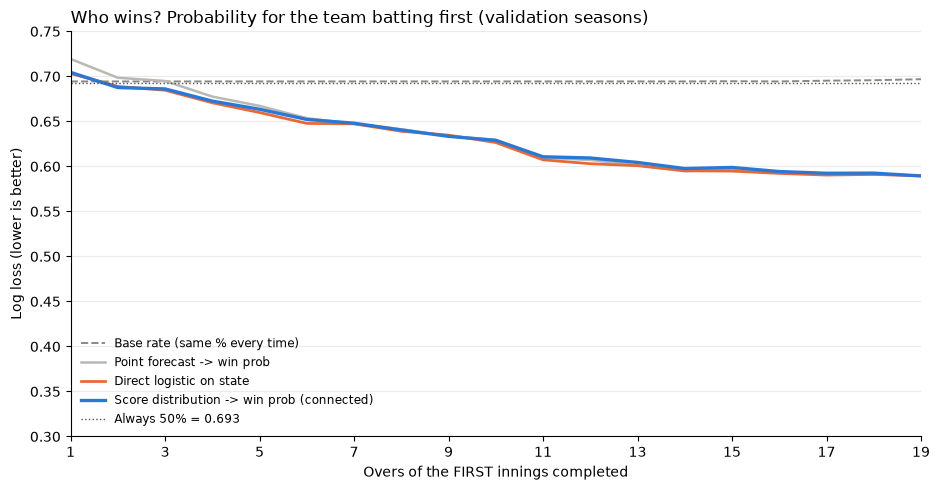

In [10]:
GRAY, GRAY2, BLUE, ORANGE = "#8a8984", "#b9b8b2", "#2a78d6", "#eb6834"
fig, ax = plt.subplots(figsize=(9.5, 5))
for name, col, ls, lw in ((F_BASE, GRAY, "--", 1.4), (F_POINT, GRAY2, "-", 1.8), (F_DIRECT, ORANGE, "-", 2.0), (F_INT, BLUE, "-", 2.4)):
    ax.plot(f_ll.index, f_ll[name], color=col, ls=ls, lw=lw, label=name)
ax.axhline(np.log(2), color="#52514e", lw=1, ls=":", label="Always 50%% = %.3f" % np.log(2))
ax.set_ylim(0.3, 0.75)
ax.set_xlim(1, 19); ax.set_xticks(range(1, 20, 2))
ax.set_xlabel("Overs of the FIRST innings completed"); ax.set_ylabel("Log loss (lower is better)")
ax.set_title("Who wins? Probability for the team batting first (validation seasons)", loc="left")
ax.legend(frameon=False, loc="lower left", fontsize=8.5); ax.grid(axis="y", alpha=0.25)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "first_innings_win_probability_logloss.png", dpi=150)
plt.show()

## 7. Final holdout (2026) - evaluated once
All models are fitted on development data only. The table at the end is the **whole-match timeline**: log loss of each stage versus
the know-nothing base rate, with a match-level bootstrap interval on the gain.

In [11]:
print("Holdout matches:", len(hold_m), "(small sample - read the CIs)")
sd_dev, start_dev, direct_dev = ScoreDist().fit(dev1), StartModel().fit(dev_m), DirectFirst().fit(dev1)
chase_dev = LogisticChase().fit(dev2)
base_first = 1 - dev_m["chase_won"].mean()

# first innings
p_int, p_pt, mid_pred = p_bat_first(sd_dev, start_dev, hold1)
yh = hold1["y"].to_numpy()
h_first = pd.concat([pd.DataFrame({"match_id": hold1["match_id"].to_numpy(), "over": hold1["over"].to_numpy(), "model": n,
                                   "y": yh, "p": p, "m": logloss(yh, p)})
                     for n, p in ((F_BASE, np.full(len(hold1), base_first)), (F_POINT, p_pt), (F_INT, p_int),
                                  (F_DIRECT, direct_dev.predict(hold1)))], ignore_index=True)
print("\nFirst-innings win probability, holdout log loss by over:")
display(h_first.pivot_table(index="over", columns="model", values="m", aggfunc="mean").loc[[o for o in CHECKPOINTS if o in set(h_first["over"])]].round(3))
h_first_cmp = compare(h_first, F_PAIRS, overs=[o for o in CHECKPOINTS if o in set(h_first["over"])] + ["ALL"])
show_compare(h_first_cmp, "log loss")

# innings break and chase
p_break = start_dev.predict(hold_m["target"], hold_m["league_recent"], hold_m["venue_effect"], hold_m["chase_rate_recent"])
y_break = hold_m["chase_won"].to_numpy()
h_break = pd.concat([pd.DataFrame({"match_id": hold_m["match_id"].to_numpy(), "over": 0, "model": n, "m": logloss(y_break, p)})
                     for n, p in (("base", np.full(len(hold_m), dev_m["chase_won"].mean())), ("model", p_break))])
p_chase = chase_dev.predict_proba1(hold2)
y_c = hold2["y"].to_numpy()
h_chase = pd.concat([pd.DataFrame({"match_id": hold2["match_id"].to_numpy(), "over": hold2["over"].to_numpy(), "model": n,
                                   "m": logloss(y_c, p)})
                     for n, p in (("base", np.full(len(hold2), dev_m["chase_won"].mean())), ("model", p_chase))])

rows = []
def add_stage(label, preds, model_name, base_name, over):
    t = per_match_table(preds, over)
    g, lo, hi = boot_mean_ci((t[base_name] - t[model_name]).to_numpy())
    rows.append(dict(stage=label, n_matches=len(t), base_log_loss=t[base_name].mean(), model_log_loss=t[model_name].mean(),
                     gain=g, ci_lo=lo, ci_hi=hi, verdict="better than base" if lo > 0 else ("worse" if hi < 0 else "noise")))
for o in [o for o in CHECKPOINTS if o in set(h_first["over"])]:
    add_stage("1st innings, over %d" % o, h_first, F_INT, F_BASE, o)
add_stage("Innings break (target known)", h_break, "model", "base", 0)
for o in [o for o in CHECKPOINTS if o in set(h_chase["over"])]:
    add_stage("Chase, over %d" % o, h_chase, "model", "base", o)
timeline = pd.DataFrame(rows)
print("\nWhole-match timeline, 2026 holdout (gain = base log loss - model log loss):")
display(timeline.set_index("stage").round(3))
timeline.to_csv(REPORTS_DIR / "match_timeline_holdout.csv", index=False)
f_compare.to_csv(REPORTS_DIR / "first_innings_win_validation_bootstrap.csv", index=False)

Holdout matches: 70 (small sample - read the CIs)

First-innings win probability, holdout log loss by over:


model,Base rate (same % every time),Direct logistic on state,Point forecast -> win prob,Score distribution -> win prob (connected)
over,,,,
1,0.674,0.687,0.658,0.696
3,0.674,0.672,0.638,0.668
6,0.674,0.688,0.666,0.676
10,0.674,0.674,0.637,0.651
15,0.674,0.648,0.603,0.617
18,0.675,0.635,0.605,0.597



Score distribution -> win prob (connected)  vs  Point forecast -> win prob   (gain = reference log loss - challenger log loss; 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
1,70,-0.038,-0.080,0.007,noise
3,70,-0.031,-0.064,0.003,noise
6,70,-0.010,-0.032,0.010,noise
10,70,-0.014,-0.029,0.002,noise
15,70,-0.015,-0.025,-0.004,reference better
18,69,0.008,0.002,0.015,challenger better
ALL,70,-0.013,-0.029,0.002,noise



Score distribution -> win prob (connected)  vs  Direct logistic on state   (gain = reference log loss - challenger log loss; 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
1,70,-0.009,-0.037,0.018,noise
3,70,0.004,-0.020,0.028,noise
6,70,0.013,-0.014,0.039,noise
10,70,0.024,-0.007,0.054,noise
15,70,0.031,-0.001,0.062,noise
18,69,0.038,0.001,0.075,challenger better
ALL,70,0.020,-0.007,0.047,noise


... (2 outputs left out)


Direct logistic on state  vs  Base rate (same % every time)   (gain = reference log loss - challenger log loss; 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
1,70,-0.013,-0.043,0.017,noise
3,70,0.002,-0.057,0.061,noise
6,70,-0.014,-0.111,0.083,noise
10,70,-0.000,-0.103,0.104,noise
15,70,0.026,-0.094,0.137,noise
18,69,0.040,-0.100,0.164,noise
ALL,70,0.007,-0.083,0.098,noise



Whole-match timeline, 2026 holdout (gain = base log loss - model log loss):


,n_matches,base_log_loss,model_log_loss,gain,ci_lo,ci_hi,verdict
stage,,,,,,,
"1st innings, over 1",70,0.674,0.696,-0.022,-0.063,0.018,noise
"1st innings, over 3",70,0.674,0.668,0.006,-0.050,0.062,noise
"1st innings, over 6",70,0.674,0.676,-0.002,-0.095,0.091,noise
"1st innings, over 10",70,0.674,0.651,0.024,-0.073,0.117,noise
"1st innings, over 15",70,0.674,0.617,0.057,-0.066,0.168,noise
"1st innings, over 18",69,0.675,0.597,0.078,-0.061,0.206,noise
Innings break (target known),70,0.674,0.548,0.126,0.013,0.229,better than base
"Chase, over 1",70,0.674,0.612,0.062,-0.067,0.187,noise
"Chase, over 3",70,0.674,0.554,0.120,0.001,0.240,better than base


## 8. The whole match on one curve (2026 chases)
Probability that the **team batting first** wins, from over 1 of the first innings to the end of the chase. The line at over 20 is the innings break.

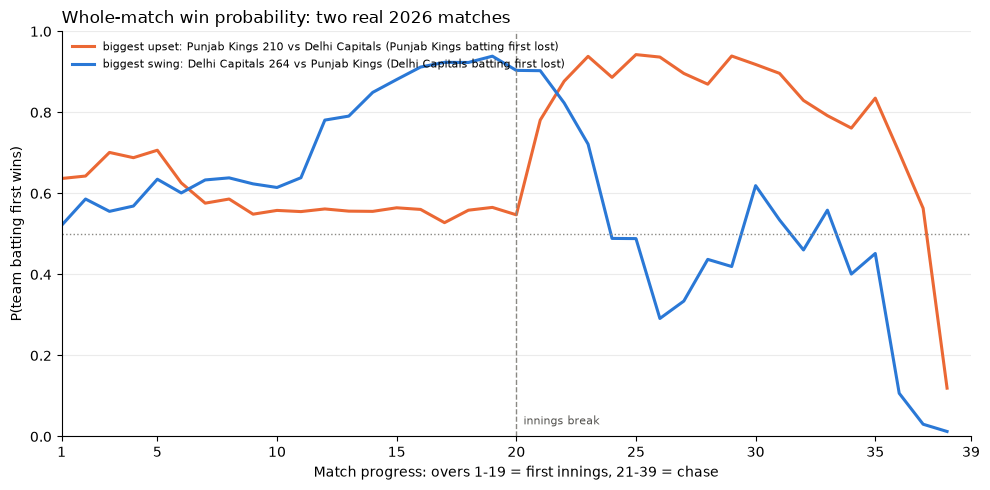


=== biggest upset: Punjab Kings 210/5 vs Delhi Capitals (target 211) | 2026-05-11 | Punjab Kings batting first LOST ===


,runs,wickets,projected_total,P(bat-first wins)
over,,,,
1,22,0,213.43,0.64
6,72,0,216.62,0.63
10,107,2,207.58,0.56
15,149,2,209.26,0.56
18,187,3,212.60,0.56



=== biggest swing: Delhi Capitals 264/2 vs Punjab Kings (target 265) | 2026-04-25 | Delhi Capitals batting first LOST ===


,runs,wickets,projected_total,P(bat-first wins)
over,,,,
1,8,0,198.86,0.52
6,68,1,215.16,0.60
10,102,1,216.46,0.61
15,189,1,257.60,0.88
18,238,1,272.57,0.92


In [12]:
info = matches.set_index("match_id")
hold1 = hold1.assign(p_first=p_int, mid_pred=mid_pred)
hold2 = hold2.assign(p_bat_first=1 - p_chase)


def match_curve(match_id):
    g1 = hold1[hold1["match_id"] == match_id].sort_values("over")
    g2 = hold2[hold2["match_id"] == match_id].sort_values("over")
    r = info.loc[match_id]
    brk = 1 - start_dev.predict([r["target"]], [r["league_recent"]], [r["venue_effect"]], [r["chase_rate_recent"]])[0]
    x = list(g1["over"]) + [20] + [20 + o for o in g2["over"]]
    y = list(g1["p_first"]) + [brk] + list(g2["p_bat_first"])
    return np.array(x), np.array(y), g1, g2


curves = {m: match_curve(m) for m in hold_m["match_id"]}
# biggest upset: most confident in the wrong side after the break; biggest swing: largest range over the whole match
wrong, swing = {}, {}
for m, (x, y, _, _) in curves.items():
    won = 1 - info.loc[m, "chase_won"]                      # did the team batting first win?
    sel = x >= 20
    wrong[m] = (1 - y[sel] if won == 1 else y[sel]).max() if sel.any() else 0
    swing[m] = y.max() - y.min()
upset_id = max(wrong, key=wrong.get)
swing_id = max((m for m in swing if m != upset_id), key=swing.get)          # a different match from the upset
picks = {"biggest upset": upset_id, "biggest swing": swing_id}

fig, ax = plt.subplots(figsize=(10, 5))
for (label, m), col in zip(picks.items(), (ORANGE, BLUE)):
    x, y, _, _ = curves[m]
    r = info.loc[m]
    ax.plot(x, y, color=col, lw=2.2, label="%s: %s %d vs %s (%s batting first %s)" % (
        label, r["team1"], r["final_score"], r["team2"], r["team1"], "won" if r["chase_won"] == 0 else "lost"))
ax.axvline(20, color=GRAY, ls="--", lw=1)
ax.axhline(0.5, color=GRAY, ls=":", lw=1)
ax.text(20.3, 0.03, "innings break", fontsize=8, color="#52514e")
ax.set_ylim(0, 1); ax.set_xlim(1, 39); ax.set_xticks([1, 5, 10, 15, 20, 25, 30, 35, 39])
ax.set_xlabel("Match progress: overs 1-19 = first innings, 21-39 = chase"); ax.set_ylabel("P(team batting first wins)")
ax.set_title("Whole-match win probability: two real 2026 matches", loc="left")
ax.legend(frameon=False, loc="upper left", fontsize=8); ax.grid(axis="y", alpha=0.25)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "whole_match_win_probability.png", dpi=150)
plt.show()

for label, m in picks.items():
    x, y, g1, g2 = curves[m]
    r = info.loc[m]
    print("\n=== %s: %s %d/%d vs %s (target %d) | %s | %s batting first %s ===" % (
        label, r["team1"], r["final_score"], parsed[m]["inn"][0]["wkts"], r["team2"], r["target"], r["date"].date(),
        r["team1"], "WON" if r["chase_won"] == 0 else "LOST"))
    sel = [o for o in (1, 6, 10, 15, 18) if o in set(g1["over"])]
    tab = g1[g1["over"].isin(sel)][["over", "runs", "wickets", "mid_pred", "p_first"]].rename(
        columns={"mid_pred": "projected_total", "p_first": "P(bat-first wins)"})
    display(tab.set_index("over").round(2))

## 9. Part 3 - Chase par-score curve
For a target `T`, an over `k` and `w` wickets down, **par** is the smallest number of runs on the board for which the chase model says
P(chasing team wins) >= 50%. Everything else (recent scoring, powerplay) is set to a *steady pace* consistent with those runs.
`margin = runs - par`: positive means ahead of par.

In [13]:
def even_state(target, k, runs, wickets):
    # steady pace: runs and wickets spread evenly over the k completed overs
    states = {i + 1: (runs * (i + 1) / k, wickets * (i + 1) / k, 0) for i in range(k)}
    return chase_features(states, k, target)


def par_runs(model, target, k, wickets, ctx):
    rs = np.arange(0, target)                                     # possible runs on the board
    df = pd.DataFrame([even_state(target, k, r, wickets) for r in rs])
    for col, v in ctx.items():
        df[col] = v
    p = model.predict_proba1(add_derived_chase(df))
    ok = np.flatnonzero(p >= 0.5)
    return (float(rs[ok[0]]) if len(ok) else np.nan), p


def context_now(venue_name, league_window=60, chase_window=100, venue_shrink=5.0):
    league = matches["final_score"].to_numpy()[-league_window:].mean()
    sub = matches[matches["venue"] == standardize_venue(venue_name)]
    return dict(league_recent=league, venue_effect=sub["excess"].sum() / (len(sub) + venue_shrink), venue_n=len(sub),
                chase_rate_recent=matches["chase_won"].to_numpy()[-chase_window:].mean())


VENUE = matches["venue"].value_counts().index[0]
ctx = context_now(VENUE)

# monotonicity check: more runs on the board must never lower the win probability
viol = 0; tot = 0
for tgt in (150, 180, 210):
    for k in (3, 6, 10, 15, 18):
        for w in (0, 3, 6):
            _, p = par_runs(chase_dev, tgt, k, w, ctx)
            viol += int(np.any(np.diff(p) < -1e-9)); tot += 1
print("Monotonicity check (P rises with runs): %d of %d tested states violate it" % (viol, tot))
print("Context used for the par tables: venue = %s | league average = %.0f | recent chase win rate = %.2f" % (
    VENUE, ctx["league_recent"], ctx["chase_rate_recent"]))

rows = []
for tgt in (160, 180, 200, 220):
    for w in (2, 4):
        row = {"target": tgt, "wickets_down": w}
        for k in (6, 10, 15, 18):
            row["par at over %d" % k] = par_runs(chase_dev, tgt, k, w, ctx)[0]
        rows.append(row)
print("\nPar score (runs needed on the board for a 50% chase), steady-pace assumption:")
display(pd.DataFrame(rows).set_index(["target", "wickets_down"]))

Monotonicity check (P rises with runs): 0 of 45 tested states violate it
Context used for the par tables: venue = Wankhede Stadium | league average = 199 | recent chase win rate = 0.59

Par score (runs needed on the board for a 50% chase), steady-pace assumption:


par at over 6  par at over 10  par at over 15  \
target wickets_down                                                  
160    2                      32.0            56.0            97.0   
       4                      53.0            71.0           104.0   
180    2                      48.0            74.0           116.0   
       4                      70.0            88.0           122.0   
200    2                      65.0            91.0           134.0   
       4                      86.0           106.0           141.0   
220    2                      81.0           108.0           153.0   
       4                     103.0           123.0           159.0   

                     par at over 18  
target wickets_down                  
160    2                      131.0  
       4                      133.0  
180    2                      150.0  
       4                      152.0  
200    2                      170.0  
       4                      172.0  
220    2                      189.0  
       4                      191.0

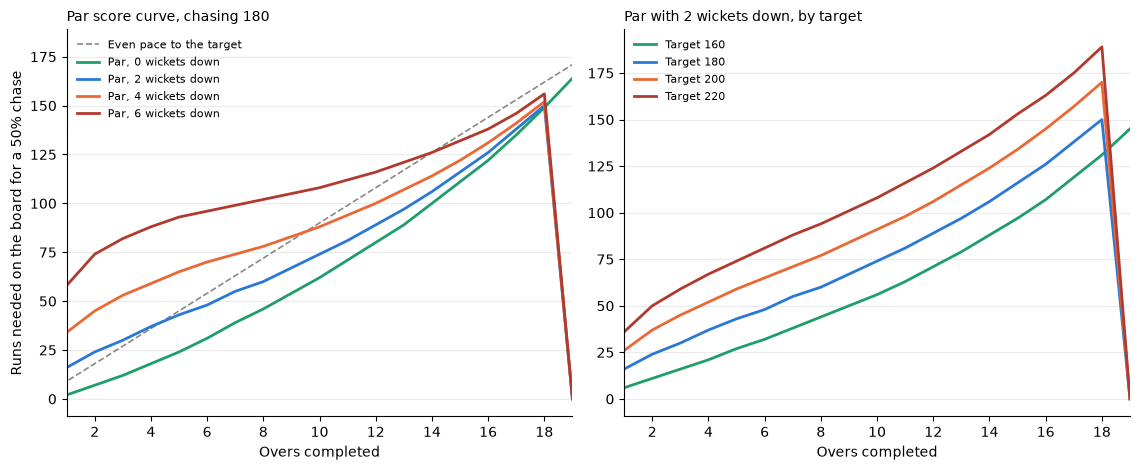

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
ks = list(range(1, 20))
COLS = {0: "#1f9d6b", 2: BLUE, 4: ORANGE, 6: "#b03a2e"}
tgt = 180
ax = axes[0]
ax.plot([0] + ks + [20], [0] + [tgt * k / 20 for k in ks] + [tgt], color=GRAY, ls="--", lw=1.2, label="Even pace to the target")
for w, col in COLS.items():
    ax.plot(ks, [par_runs(chase_dev, tgt, k, w, ctx)[0] for k in ks], color=col, lw=2, label="Par, %d wickets down" % w)
ax.set_title("Par score curve, chasing %d" % tgt, loc="left", fontsize=10)
ax.set_xlabel("Overs completed"); ax.set_ylabel("Runs needed on the board for a 50% chase")
ax.legend(frameon=False, fontsize=8); ax.set_xlim(1, 19); ax.grid(axis="y", alpha=0.25)
ax = axes[1]
for t_, col in ((160, "#1f9d6b"), (180, BLUE), (200, ORANGE), (220, "#b03a2e")):
    ax.plot(ks, [par_runs(chase_dev, t_, k, 2, ctx)[0] for k in ks], color=col, lw=2, label="Target %d" % t_)
ax.set_title("Par with 2 wickets down, by target", loc="left", fontsize=10)
ax.set_xlabel("Overs completed"); ax.legend(frameon=False, fontsize=8); ax.set_xlim(1, 19); ax.grid(axis="y", alpha=0.25)
for a in axes:
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "chase_par_score_curve.png", dpi=150)
plt.show()

In [15]:
# ---- ahead / behind par in the two real 2026 chases (each match uses its own era / venue context) ----
CTX_COLS = ["league_recent", "venue_effect", "venue_n", "chase_rate_recent"]
for label, m in picks.items():
    g2 = hold2[hold2["match_id"] == m].sort_values("over")
    r = info.loc[m]
    rows = []
    for rr in g2[g2["over"].isin([3, 6, 10, 15, 18])].itertuples():
        c = {k: getattr(rr, k) for k in CTX_COLS}
        par, _ = par_runs(chase_dev, int(rr.target), int(rr.over), int(rr.wickets), c)
        rows.append(dict(over=rr.over, runs=rr.runs, wickets=rr.wickets, par=par, margin_vs_par=rr.runs - par,
                         p_chase_wins=1 - rr.p_bat_first))
    print("\n=== %s: %s chasing %d | %s | chase %s ===" % (label, r["team2"], r["target"], r["date"].date(), "WON" if r["chase_won"] else "LOST"))
    display(pd.DataFrame(rows).set_index("over").round(2))


=== biggest upset: Delhi Capitals chasing 211 | 2026-05-11 | chase WON ===


,runs,wickets,par,margin_vs_par,p_chase_wins
over,,,,,
3,14,2,60.0,-46.0,0.06
6,47,3,91.0,-44.0,0.06
10,87,4,121.0,-34.0,0.08
15,143,5,159.0,-16.0,0.16
18,194,6,187.0,7.0,0.88



=== biggest swing: Punjab Kings chasing 265 | 2026-04-25 | chase WON ===


,runs,wickets,par,margin_vs_par,p_chase_wins
over,,,,,
3,56,0,73.0,-17.0,0.28
6,116,0,100.0,16.0,0.71
10,147,3,154.0,-7.0,0.38
15,203,4,201.0,2.0,0.55
18,252,4,234.0,18.0,0.99


## 10. Use it: the whole match, live

In [16]:
# Final models for real use: the holdout has been evaluated, so train on ALL data
sd_final, start_final, chase_final = ScoreDist().fit(snap1), StartModel().fit(matches), LogisticChase().fit(snap2)


def live_first_innings(cum_runs, cum_wickets, cum_boundaries, venue):
    k = len(cum_runs)
    assert 1 <= k <= 19 and len(cum_wickets) == k and len(cum_boundaries) == k
    states = {i + 1: (cum_runs[i], cum_wickets[i], cum_boundaries[i]) for i in range(k)}
    row = first_features(states, k)
    row.update(context_now(venue))
    row = add_linear_first(pd.DataFrame([row]))
    p_i, _, mid = p_bat_first(sd_final, start_final, row)
    lo, hi = np.quantile(mid[0] + sd_final.grid[k], [0.1, 0.9])
    return dict(projected_total=round(float(mid[0])), range_80=(round(float(lo)), round(float(hi))),
                p_batting_side_wins=round(float(p_i[0]), 3))


def live_chase(target, cum_runs, cum_wickets, venue):
    k = len(cum_runs)
    assert 1 <= k <= 19 and len(cum_wickets) == k
    states = {i + 1: (cum_runs[i], cum_wickets[i], 0) for i in range(k)}
    row = chase_features(states, k, target)
    c = context_now(venue)
    row.update(c)
    p = float(chase_final.predict_proba1(add_derived_chase(pd.DataFrame([row])))[0])
    par, _ = par_runs(chase_final, target, k, cum_wickets[-1], c)
    return dict(p_chasing_side_wins=round(p, 3), par_runs=par, margin_vs_par=cum_runs[-1] - par)


# First innings: 10 overs done, 92/2
runs1 = [7, 15, 24, 31, 38, 50, 58, 68, 79, 92]; wk1 = [0, 0, 0, 1, 1, 1, 1, 2, 2, 2]; b1 = [1, 2, 3, 4, 5, 7, 8, 9, 10, 12]
print("First innings at %s, 92/2 after 10 overs:" % VENUE, live_first_innings(runs1, wk1, b1, VENUE))
# Chase: target 186, 98/3 after 12 overs
runs2 = [6, 14, 25, 33, 41, 55, 63, 72, 80, 88, 93, 98]; wk2 = [0, 0, 0, 1, 1, 1, 2, 2, 2, 3, 3, 3]
print("Chase of 186 at %s, 98/3 after 12 overs:" % VENUE, live_chase(186, runs2, wk2, VENUE))

First innings at Wankhede Stadium, 92/2 after 10 overs: {'projected_total': 203, 'range_80': (175, 231), 'p_batting_side_wins': 0.468}
Chase of 186 at Wankhede Stadium, 98/3 after 12 overs: {'p_chasing_side_wins': 0.595, 'par_runs': 94.0, 'margin_vs_par': 4.0}


## Export for the dashboard
Writes `nb06.json` into `dashboard/public/data/` (override with the `IPL_DASHBOARD_DATA` environment variable). The React dashboard reads these files.
This cell only reads results that are already in memory, so run it **after** the cells above.

In [17]:
# ===== Dashboard export =====================================================================
# Writes JSON files that the React dashboard reads. Safe to re-run; it only writes files.
import json, datetime

DASH_DIR = Path(os.environ.get("IPL_DASHBOARD_DATA", PROJECT_ROOT / "dashboard" / "public" / "data"))
DASH_DIR.mkdir(parents=True, exist_ok=True)


def _clean(x):
    if isinstance(x, dict):
        return {str(k): _clean(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_clean(v) for v in x]
    if isinstance(x, pd.DataFrame):
        return _clean(x.reset_index().to_dict("records"))
    if isinstance(x, pd.Series):
        return _clean(x.to_dict())
    if isinstance(x, np.ndarray):
        return _clean(x.tolist())
    if isinstance(x, (bool, np.bool_)):
        return bool(x)
    if isinstance(x, (int, np.integer)):
        return int(x)
    if isinstance(x, (float, np.floating)):
        return round(float(x), 5) if np.isfinite(x) else None
    if isinstance(x, (pd.Timestamp, datetime.date)):
        return str(x)[:10]
    if x is None or isinstance(x, str):
        return x
    return str(x)


def tbl(df, scale=1.0):
    # pivot-style table -> {"index": [...], "columns": [...], "data": [[...]]}
    d = df.astype(float) * scale
    return {"index": _clean(list(d.index)), "columns": [str(c) for c in d.columns], "data": _clean(d.values.tolist())}


def recs(df):
    d = df.copy()
    for c in d.columns:
        if str(d[c].dtype).startswith("category") or d[c].dtype == object:
            d[c] = d[c].astype(str)
    return _clean(d.reset_index(drop=True).to_dict("records"))


def dash_save(name, payload):
    meta = {"notebook": name, "generated": datetime.datetime.now().isoformat(timespec="seconds"),
            "matches": int(len(matches)), "first_season": int(matches["season"].min()), "last_season": int(matches["season"].max())}
    path = DASH_DIR / (name + ".json")
    path.write_text(json.dumps(_clean({"meta": meta, **payload}), separators=(",", ":")), encoding="utf-8")
    print("wrote %s (%.0f KB)" % (path, path.stat().st_size / 1024))

# ---- 1. result tables ----
d_ = s_preds[s_preds["model"] == S_MODEL]
t_s, ece_s = calibration_table(d_["p"].to_numpy(), d_["y"].to_numpy(), bins=5)
start_block = {"log_loss": {"base": float(s_preds[s_preds["model"] == S_BASE]["m"].mean()), "model": float(d_["m"].mean())},
               "compare": recs(compare(s_preds, [(S_MODEL, S_BASE)], overs=[0])), "ece": float(ece_s), "calibration": recs(t_s.reset_index(drop=True))}
cal_f = {}
for name in (F_INT, F_DIRECT):
    dd = f_preds[f_preds["model"] == name]
    t_, e_ = calibration_table(dd["p"].to_numpy(), dd["y"].to_numpy())
    cal_f[name] = {"ece": float(e_), "bins": recs(t_.reset_index(drop=True))}
h_first_ll = h_first.pivot_table(index="over", columns="model", values="m", aggfunc="mean")
f_acc = f_preds.pivot_table(index="over", columns="model", values="correct", aggfunc="mean")

# ---- 2. the two real 2026 match curves (both views) ----
def replay_block(m):
    r = info.loc[m]
    g1 = hold1[hold1["match_id"] == m].sort_values("over")
    g2 = hold2[hold2["match_id"] == m].sort_values("over")
    brk = 1 - start_dev.predict([r["target"]], [r["league_recent"]], [r["venue_effect"]], [r["chase_rate_recent"]])[0]
    chase_rows = []
    for rr in g2.itertuples():
        c = {k: getattr(rr, k) for k in ["league_recent", "venue_effect", "venue_n", "chase_rate_recent"]}
        par_, _ = par_runs(chase_dev, int(rr.target), int(rr.over), int(rr.wickets), c)
        chase_rows.append(dict(over=int(rr.over), runs=float(rr.runs), wickets=int(rr.wickets), par=par_, p_chase=float(1 - rr.p_bat_first)))
    return dict(match_id=str(m), date=r["date"], team_first=r["team1"], team_chase=r["team2"], venue=r["venue"], target=int(r["target"]),
                first_final=int(r["final_score"]), first_wkts=int(parsed[m]["inn"][0]["wkts"]), chase_won=int(r["chase_won"]),
                p_break_batting_first=float(brk),
                first=recs(g1[["over", "runs", "wickets", "mid_pred", "p_first"]].rename(columns={"mid_pred": "projected_total", "p_first": "p_bat_first"})),
                chase=chase_rows)

replays = {label: replay_block(m) for label, m in picks.items()}

# ---- 3. context + venue list used by the grids ----
VENUE_LIST = matches["venue"].value_counts().head(25).index.tolist()
ctx0 = context_now(VENUE)
venues_tbl = [dict(venue=v, matches=int((matches["venue"] == v).sum()),
                   venue_effect=float(context_now(v)["venue_effect"]), chase_win=float(matches.loc[matches["venue"] == v, "chase_won"].mean()),
                   avg_first=float(matches.loc[matches["venue"] == v, "final_score"].mean())) for v in VENUE_LIST]

# ---- 4. par table from the final chase model (steady-pace assumption) ----
PAR_TARGETS, PAR_WK, PAR_OVERS_ = list(range(140, 261, 10)), list(range(0, 9)), [3, 6, 9, 12, 15, 18]
par_grid = [[[par_runs(chase_final, T, k, w, ctx0)[0] for k in PAR_OVERS_] for w in PAR_WK] for T in PAR_TARGETS]

# ---- 5. grids from the TRAINED models: the dashboard interpolates in these ----
def fast_state(k, runs, wk, bnd=0.0):
    # same as even_state: runs / wickets spread evenly over k overs; only the keys the features read are built
    keys = {k, k - 5, k - 3, min(k, 6)}
    return {j: (runs * j / k, wk * j / k, bnd * j / k) for j in keys if j >= 1}

VE_LIST = [-10.0, 0.0, 10.0]
G_T, G_K, G_W = list(range(120, 261, 10)), list(range(1, 20)), list(range(0, 10))
G_F = [round(0.05 * i, 2) for i in range(0, 20)]              # runs on the board as a fraction of the target (0 .. 0.95)
chase_p = []
for ve in VE_LIST:
    rows_ = []
    for T in G_T:
        for k in G_K:
            for w in G_W:
                for f_ in G_F:
                    st = fast_state(k, f_ * T, w)
                    rows_.append(chase_features(st, k, T))
    gdf = pd.DataFrame(rows_)
    for col, v in ctx0.items():
        gdf[col] = v
    gdf["venue_effect"] = ctx0["venue_effect"] + ve
    chase_p.extend(np.round(chase_final.predict_proba1(add_derived_chase(gdf)), 3).tolist())

G_RR = list(range(3, 19))                                      # run rate so far
first_out = {"proj": [], "lo": [], "hi": [], "p": []}
for ve in VE_LIST:
    rows_ = []
    for k in G_K:
        for w in G_W:
            for rr_ in G_RR:
                runs_ = rr_ * k
                row = first_features(fast_state(k, runs_, w, 0.12 * runs_), k)
                row.update(ctx0)
                row["venue_effect"] = ctx0["venue_effect"] + ve
                rows_.append(row)
    gdf = add_linear_first(pd.DataFrame(rows_))
    p_i, _, mid = p_bat_first(sd_final, start_final, gdf)
    draws = mid[:, None] + sd_final.draws(gdf)
    lo, hi = np.quantile(draws, [0.1, 0.9], axis=1)
    first_out["proj"] += np.round(mid, 1).tolist(); first_out["lo"] += np.round(lo, 1).tolist()
    first_out["hi"] += np.round(hi, 1).tolist(); first_out["p"] += np.round(p_i, 3).tolist()

SC_T = list(range(100, 301, 5))
start_curve = {"ve": VE_LIST, "targets": SC_T, "p": [round(float(p), 4) for ve in VE_LIST for p in start_final.predict(
    SC_T, [ctx0["league_recent"]] * len(SC_T), [ctx0["venue_effect"] + ve] * len(SC_T), [ctx0["chase_rate_recent"]] * len(SC_T))]}

payload = {
    "start_curve": start_curve,
    "start_of_chase": start_block,
    "first_innings": {"logloss_validation": tbl(f_ll), "accuracy_validation": tbl(f_acc, 100.0), "compare_validation": recs(f_compare),
                      "calibration": cal_f, "logloss_holdout": tbl(h_first_ll), "compare_holdout": recs(h_first_cmp)},
    "timeline_holdout": recs(timeline),
    "replays": replays,
    "context": {"venue": VENUE, **{k: float(v) if np.isscalar(v) else v for k, v in ctx0.items()}}, "venues": venues_tbl,
    "par": {"targets": PAR_TARGETS, "wickets": PAR_WK, "overs": PAR_OVERS_, "values": par_grid, "venue": VENUE},
    "grid_chase": {"ve": VE_LIST, "targets": G_T, "overs": G_K, "wickets": G_W, "frac": G_F, "p": chase_p,
                   "order": "ve, target, over, wickets, frac (row-major)"},
    "grid_first": {"ve": VE_LIST, "overs": G_K, "wickets": G_W, "run_rate": G_RR, **first_out,
                   "order": "ve, over, wickets, run_rate (row-major); boundaries assumed 0.12 per run"},
}
dash_save("nb06", payload)

wrote c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\dashboard\public\data\nb06.json (1132 KB)


In [18]:
# ===== Per-match export for the dashboard (paste as a NEW LAST CELL) ========================
import json, datetime

DASH_DIR = Path(os.environ.get("IPL_DASHBOARD_DATA", PROJECT_ROOT / "dashboard" / "public" / "data"))
DASH_DIR.mkdir(parents=True, exist_ok=True)
OVERS = list(range(1, 20))                                   # overs 1..19 (the over-20 state is the final score)


def pack_by_match(df, col, nd=3):
    # one list of 19 numbers per match (index 0 = over 1); None where that over has no row
    piv = df.pivot_table(index="match_id", columns="over", values=col, aggfunc="first").reindex(columns=OVERS)
    return {str(mid): [None if pd.isna(v) else round(float(v), nd) for v in row] for mid, row in zip(piv.index, piv.values)}


def merge_save(file, section, payload):
    # predictions.json is shared by notebooks 03, 04 and 06: each one only replaces its own section
    path = DASH_DIR / (file + ".json")
    cur = {}
    if path.exists():
        try:
            cur = json.loads(path.read_text(encoding="utf-8"))
        except Exception:
            cur = {}
    meta = cur.get("meta", {})
    meta.update({"generated": datetime.datetime.now().isoformat(timespec="seconds"), "matches": int(len(matches)),
                 "first_season": int(matches["season"].min()), "last_season": int(matches["season"].max())})
    cur["meta"] = meta
    cur[section] = payload
    meta["sections"] = sorted(k for k in cur if k != "meta")
    path.write_text(json.dumps(cur, separators=(",", ":")), encoding="utf-8")
    print("wrote %s section '%s' (file now %.0f KB)" % (path, section, path.stat().st_size / 1024))

# 1) first-innings win probability (connected model), 2) start-of-chase probability, 3) chase probability from this notebook's
#    chase model, 4) chase par score for every match. 1-3 are out-of-sample (validation 2021-25, holdout 2026).
#    Par is a reference curve from the FINAL chase model (fit on 2008-2025): out-of-sample for 2026, in-sample before that.
_split = {}
_first = pd.concat([f_preds[f_preds["model"] == F_INT][["match_id", "over", "p"]],
                    h_first[h_first["model"] == F_INT][["match_id", "over", "p"]]], ignore_index=True)
_split.update({str(m): "val" for m in f_preds["match_id"].unique()})
_split.update({str(m): "hold" for m in h_first["match_id"].unique()})

_vs = s_preds[s_preds["model"] == S_MODEL]
_p0 = dict(zip(_vs["match_id"].astype(str), np.round(_vs["p"].to_numpy(), 4).tolist()))
_p0.update(dict(zip(hold_m["match_id"].astype(str), np.round(np.asarray(p_break), 4).tolist())))

_c = []
for _f in folds:
    _tr, _va = dev2[dev2["season"] <= _f["train_through"]], dev2[dev2["season"] == _f["validate"]]
    _c.append(_va[["match_id", "over"]].assign(p=LogisticChase().fit(_tr).predict_proba1(_va)))
_c.append(hold2[["match_id", "over"]].assign(p=np.asarray(p_chase)))
_chase = pd.concat(_c, ignore_index=True)

_CTX = ["league_recent", "venue_effect", "venue_n", "chase_rate_recent"]
_s2 = snap2[["match_id", "over", "target", "wickets"] + _CTX].reset_index(drop=True)


def _par_all(model, s):
    # smallest runs on the board with P(chase wins) >= 50% (same definition as par_runs), found by bisection for all states at once
    tgt, ks, ws = s["target"].to_numpy(int), s["over"].to_numpy(int), s["wickets"].to_numpy(int)
    ctx = s[_CTX].reset_index(drop=True)
    lo, hi = np.zeros(len(s), dtype=int), tgt - 1
    def p_at(r):
        d = pd.DataFrame([even_state(int(t), int(k), float(x), int(w)) for t, k, x, w in zip(tgt, ks, r, ws)])
        for c in _CTX:
            d[c] = ctx[c].to_numpy()
        return model.predict_proba1(add_derived_chase(d))
    while (lo < hi).any():
        mid = (lo + hi) // 2
        ok = p_at(mid) >= 0.5
        hi = np.where(ok, mid, hi)
        lo = np.where(ok, lo, np.minimum(mid + 1, hi))
    return np.where(p_at(lo) >= 0.5, lo, np.nan)


_s2["par"] = _par_all(chase_dev, _s2)
_pf, _pc, _pp = pack_by_match(_first, "p", nd=4), pack_by_match(_chase, "p", nd=4), pack_by_match(_s2, "par", nd=0)
_out = {}
for _m in _pp:
    e = {"split": _split.get(_m, "train"), "par": _pp[_m]}
    if _m in _pf: e["p_first"] = _pf[_m]
    if _m in _p0: e["p_start"] = _p0[_m]
    if _m in _pc: e["p_chase"] = _pc[_m]
    _out[_m] = e
merge_save("predictions", "nb06", {
    "overs": OVERS, "par_basis": "final chase model fit on 2008-2025, steady-pace assumption, 50% line",
    "models": {"first": str(F_INT), "start": str(S_MODEL), "chase": str(LogisticChase.name)},
    "matches": _out,
})

wrote c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\dashboard\public\data\predictions.json section 'nb06' (file now 501 KB)
